In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Descripción de atributos: NYC Taxi Trip Duration

Tablas y gráficas descriptivas de cada atributo del conjunto `train.csv`. No se modifica el dataset.

**Contenido**
1. Carga de datos
2. Atributos categóricos y discretos (`vendor_id`, `passenger_count`, `store_and_fwd_flag`)
3. Atributos numéricos continuos (coordenadas y `trip_duration`)
4. Atributos temporales (rangos)

Las figuras se guardan en `diagramas/` para incluirlas en la memoria.

## 1. Carga de datos

In [2]:
# Carga de datos
PATH = "train.csv"
OUT = "diagramas"
os.makedirs(OUT, exist_ok=True)

df = pd.read_csv(PATH, parse_dates=["pickup_datetime", "dropoff_datetime"])
sns.set_theme(style="whitegrid")

## 2. Atributos categóricos y discretos

Para cada uno: tabla de frecuencias (con porcentaje) y diagrama de barras.
`passenger_count` y `store_and_fwd_flag` tienen valores muy poco frecuentes, por eso sus barras usan **escala logarítmica** en el eje y.

--- vendor_id ---
 Valor  Frecuencia  Porcentaje (%)
     1      678342            46.5
     2      780302            53.5 



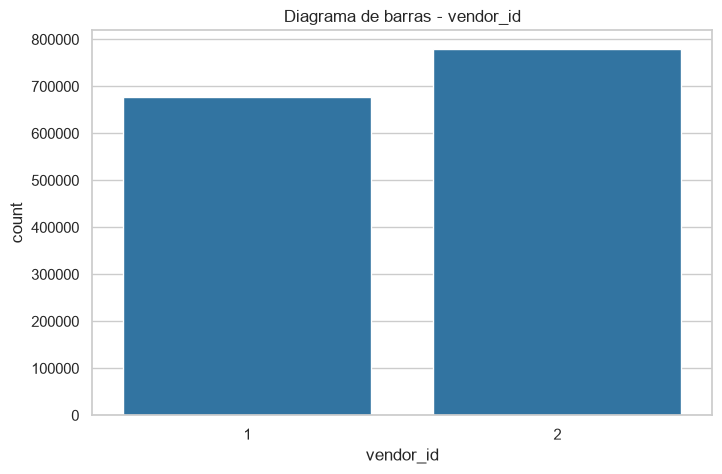

--- passenger_count ---
 Valor  Frecuencia  Porcentaje (%)
     0          60            0.00
     1     1033540           70.86
     2      210318           14.42
     3       59896            4.11
     4       28404            1.95
     5       78088            5.35
     6       48333            3.31
     7           3            0.00
     8           1            0.00
     9           1            0.00 



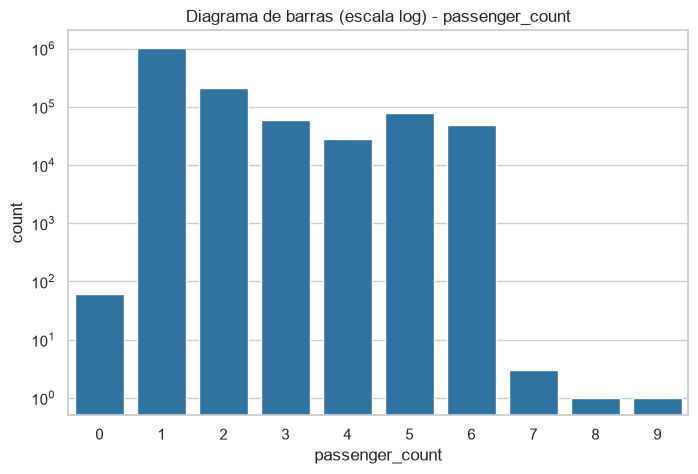

--- store_and_fwd_flag ---
Valor  Frecuencia  Porcentaje (%)
    N     1450599           99.45
    Y        8045            0.55 



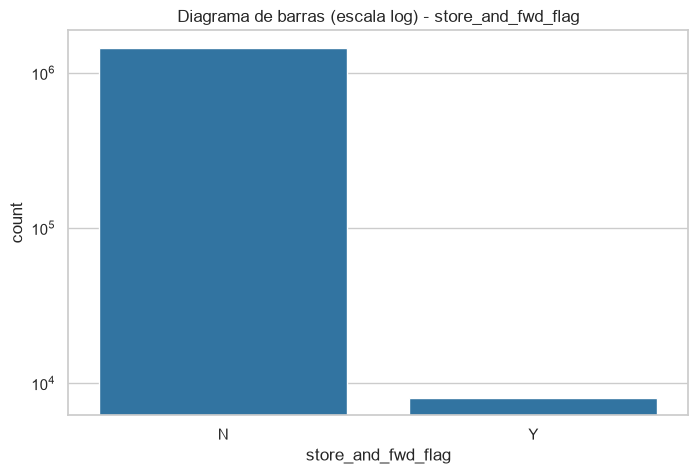

In [3]:
categorical_cols = ["vendor_id", "passenger_count", "store_and_fwd_flag"]
log_bars = ["passenger_count", "store_and_fwd_flag"]   # barras con eje y logarítmico


def frequency_table(col):
    """Frecuencia y porcentaje de cada valor de `col` (ordenado por valor)."""
    table = df[col].value_counts(dropna=False).reset_index()
    table.columns = ["Valor", "Frecuencia"]
    table = table.sort_values("Valor").reset_index(drop=True)
    table["Porcentaje (%)"] = (table["Frecuencia"] / len(df) * 100).round(2)
    return table


def bar_plot(col, order, log=False):
    """Diagrama de barras de `col`; se guarda en OUT/barras_<col>.png."""
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x=col, color="tab:blue", order=order)
    if log:
        plt.yscale("log")
        plt.title(f"Diagrama de barras (escala log) - {col}")
    else:
        plt.title(f"Diagrama de barras - {col}")
    plt.savefig(f"{OUT}/barras_{col}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()


for col in categorical_cols:
    freq = frequency_table(col)
    print(f"--- {col} ---")
    print(freq.to_string(index=False), "\n")
    bar_plot(col, order=freq["Valor"], log=col in log_bars)

## 3. Atributos numéricos continuos

Tabla con mínimo, máximo, media, mediana, moda, desviación típica y número de valores distintos, e histogramas con escala logarítmica en el eje y (para que se vea la cola con los valores extremos).

In [8]:
numeric_cols = ["pickup_longitude", "pickup_latitude",
                "dropoff_longitude", "dropoff_latitude", "trip_duration"]

summary = df[numeric_cols].agg(["min", "max", "mean", "median", "std"]).T
summary.columns = ["Mínimo", "Máximo", "Media", "Mediana", "Desv. típica"]
summary["Moda"] = df[numeric_cols].mode().iloc[0]    # si hay varias, se toma la primera
summary["Valores distintos"] = df[numeric_cols].nunique()

summary = summary[["Mínimo", "Máximo", "Media", "Mediana", "Moda",
                   "Desv. típica", "Valores distintos"]]
print(summary.round(4).to_string())

                     Mínimo        Máximo     Media   Mediana      Moda  Desv. típica  Valores distintos
pickup_longitude  -121.9333 -6.133550e+01  -73.9735  -73.9817  -73.9822        0.0709              23047
pickup_latitude     34.3597  5.188110e+01   40.7509   40.7541   40.7741        0.0329              45245
dropoff_longitude -121.9333 -6.133550e+01  -73.9734  -73.9798  -73.9823        0.0706              33821
dropoff_latitude    32.1811  4.392100e+01   40.7518   40.7545   40.7743        0.0359              62519
trip_duration        1.0000  3.526282e+06  959.4923  662.0000  368.0000     5237.4317               7417


In [5]:
# Forma de la distribución (apéndice). La curtosis de pandas es en exceso: normal = 0
shape = pd.DataFrame({
    "Asimetría": df[numeric_cols].skew(),
    "Curtosis (exceso)": df[numeric_cols].kurtosis(),
})
print(shape.round(2).to_string())

                   Asimetría  Curtosis (exceso)
pickup_longitude     -418.12          288156.52
pickup_latitude         5.49           12950.24
dropoff_longitude    -425.33          292526.02
dropoff_latitude      -20.67            4259.54
trip_duration         343.16          192131.52


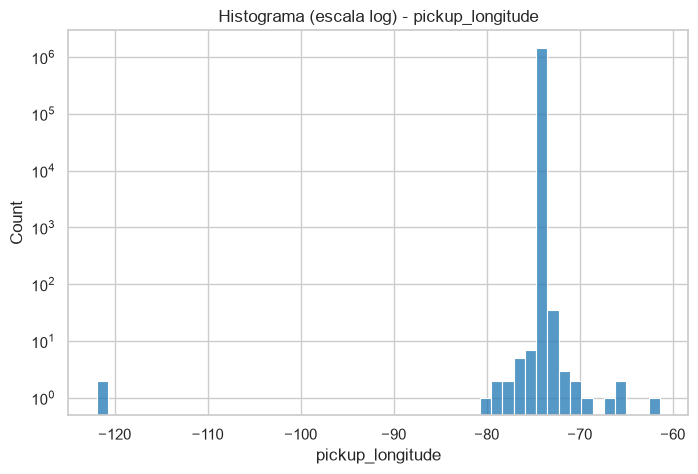

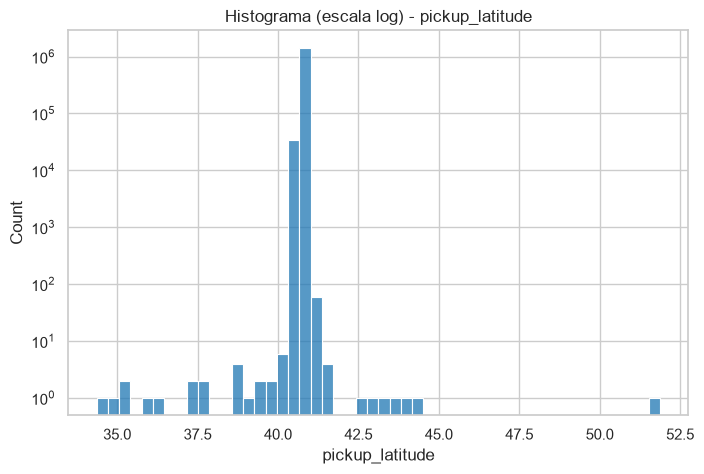

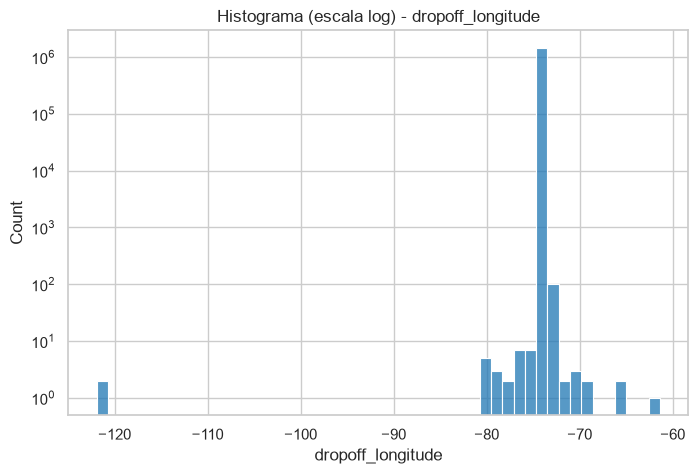

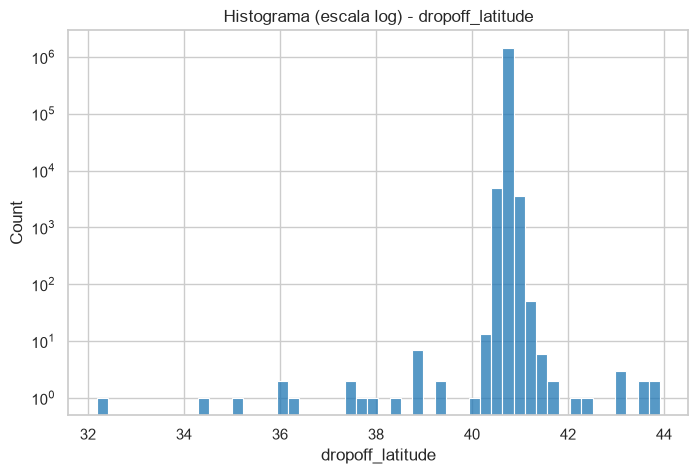

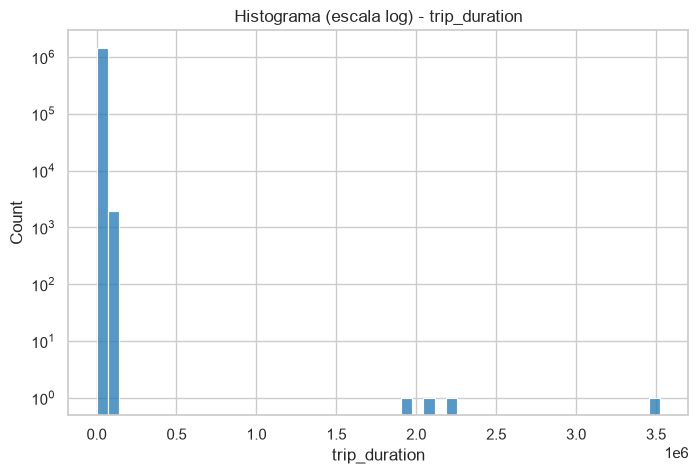

In [6]:
for col in numeric_cols:
    plt.figure(figsize=(8, 5))
    sns.histplot(df[col], bins=50, color="tab:blue")
    plt.yscale("log")
    plt.title(f"Histograma (escala log) - {col}")
    plt.savefig(f"{OUT}/hist_{col}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

## 4. Atributos nominales (marcas temporales)

`pickup_datetime` y `dropoff_datetime` son nominales (marcas temporales): no tiene sentido calcular una media, así que solo se muestran sus rangos (primer y último valor).

In [7]:
temporal_cols = ["pickup_datetime", "dropoff_datetime"]

for col in temporal_cols:
    print(f"--- {col} ---")
    print("Mínimo:", df[col].min())
    print("Máximo:", df[col].max(), "\n")

--- pickup_datetime ---
Mínimo: 2016-01-01 00:00:17
Máximo: 2016-06-30 23:59:39 

--- dropoff_datetime ---
Mínimo: 2016-01-01 00:03:31
Máximo: 2016-07-01 23:02:03 

